<a href="https://colab.research.google.com/github/Moreno04181/unidad2-caso-b-bases-de-datos/blob/main/notebooks/Caso_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad Integradora — Unidad 2
## Inferencia Estadística y Toma de Decisiones en Ingeniería
**Caso B: Motores de Base de Datos (PostgreSQL vs. MongoDB)**

- **Asignatura:** Fundamentos de Ciencia de Datos — TecNM / ITZ
- **Carrera:** Ingeniería en Sistemas Computacionales
- **Equipo:** *JESUS ALEJANDRO MORENO VARGAS, SANTIAGO OCAMPO CASTRO*
- **Docente:** *RAMOS PALENCIA CELIA*
- **Fecha:** *18/10/2026*

## 0. Contexto, objetivo y metodología

**Problema.** Contrastar si existe diferencia en el tiempo de procesamiento de transacciones mixtas (lecturas y escrituras) entre un motor relacional (PostgreSQL) y uno documental (MongoDB).

**Variables.**
- Variable cuantitativa (Y): `tiempo_ms`, tiempo de ejecución por transacción en milisegundos.
- Variable cualitativa (X): `motor`, con dos niveles (PostgreSQL, MongoDB).

**Objetivo.** Aplicar estadística descriptiva, simulación del Teorema Central del Límite (TCL), estimación por intervalos de confianza y prueba de hipótesis paramétrica para sustentar una decisión técnica formal.

**Metodología.** El notebook sigue los cuatro bloques de la actividad. Cada bloque se compone de una celda de texto (qué se hace y por qué) y una celda de código (cómo se hace). Se fija la semilla aleatoria para que los resultados sean reproducibles.

**Origen de los datos (generación sintética justificada).** No se dispuso de un dataset público de tiempos por transacción con 200 o más observaciones por motor, por lo que se simularon mediante distribuciones teóricas. Se eligió la distribución **gamma desplazada** porque los tiempos de ejecución son siempre positivos, tienen un mínimo físico (costo fijo de conexión y parseo) y presentan sesgo a la derecha (algunas transacciones se ralentizan por bloqueos o caché fría), comportamiento típico de métricas de latencia.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ---- Configuración global (un solo lugar para cambiar parámetros) ----
SEED = 42
ALPHA = 0.05
VAR = "tiempo_ms"          # variable cuantitativa (Y)
GRUPO = "motor"            # variable cualitativa (X)
G1, G2 = "PostgreSQL", "MongoDB"

# El notebook vive en notebooks/ y los datos en data/ (estructura del repositorio)
RUTA_DATA = Path("data")
RUTA_DATA.mkdir(parents=True, exist_ok=True)
ARCHIVO_ORIGINAL = RUTA_DATA / "dataset_caso_b.csv"
ARCHIVO_DEPURADO = RUTA_DATA / "dataset_caso_b_depurado.csv"

### 0.1 Generación del dataset

Se generan **300 observaciones por motor** (N = 600). Se usan más de las 200 mínimas porque el Bloque 1 elimina valores atípicos y se debe conservar al menos 200 por grupo (N ≥ 400) después de la limpieza.

Parámetros usados:
- PostgreSQL: gamma(forma = 3.0, escala = 4.0) + 8 ms
- MongoDB: gamma(forma = 2.8, escala = 4.5) + 9 ms

In [2]:
def generar_dataset(n_por_grupo=300, seed=SEED):
    """Genera tiempos de ejecución por transacción (ms) para ambos motores."""
    rng = np.random.default_rng(seed)
    t_pg = rng.gamma(shape=3.0, scale=4.0, size=n_por_grupo) + 8
    t_mongo = rng.gamma(shape=2.8, scale=4.5, size=n_por_grupo) + 9
    return pd.DataFrame({
        VAR: np.concatenate([t_pg, t_mongo]),
        GRUPO: [G1] * n_por_grupo + [G2] * n_por_grupo,
    })

df_original = generar_dataset()
df_original.to_csv(ARCHIVO_ORIGINAL, index=False)
print(f"Dataset original guardado en {ARCHIVO_ORIGINAL} con {len(df_original)} registros")

Dataset original guardado en data/dataset_caso_b.csv con 600 registros


# Bloque 1. Estadística descriptiva y limpieza

### 1.1 Carga y verificación de calidad de datos

**Qué se hace:** se carga el CSV en un DataFrame de Pandas y se revisan tres cosas: los primeros registros, los tipos de dato (`tiempo_ms` debe ser numérico y `motor` categórico/texto) y los valores ausentes.

**Por qué:** cualquier análisis posterior asume datos completos y con el tipo correcto; un tipo erróneo o un nulo no detectado distorsiona medias y varianzas.

In [3]:
df = pd.read_csv(ARCHIVO_ORIGINAL)

print("Primeros registros:")
display(df.head())

print("\nTipos de datos e información general:")
df.info()

print("\nValores ausentes por columna:")
print(df.isnull().sum())

print("\nObservaciones por grupo:")
print(df[GRUPO].value_counts())

Primeros registros:


,tiempo_ms,motor
0,20.783440,PostgreSQL
1,24.357838,PostgreSQL
2,19.523697,PostgreSQL
3,18.557298,PostgreSQL
4,25.503689,PostgreSQL



Tipos de datos e información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   tiempo_ms  600 non-null    float64
 1   motor      600 non-null    object 
dtypes: float64(1), object(1)
memory usage: 9.5+ KB

Valores ausentes por columna:
tiempo_ms    0
motor        0
dtype: int64

Observaciones por grupo:
motor
PostgreSQL    300
MongoDB       300
Name: count, dtype: int64


### 1.2 Detección y remoción de valores atípicos (criterio 1.5 × IQR)

**Qué se hace:** para **cada grupo por separado** se calculan el primer cuartil (Q1), el tercero (Q3) y el rango intercuartílico IQR = Q3 − Q1. Se consideran atípicos los valores fuera del intervalo

$$[\,Q_1 - 1.5\cdot IQR,\; Q_3 + 1.5\cdot IQR\,]$$

**Por qué por grupo:** cada motor tiene su propia distribución; un valor normal en uno puede ser atípico en el otro. Calcular los límites sobre la columna completa mezclaría ambas distribuciones.

Después de limpiar se verifica que se conserve al menos 200 observaciones por grupo y N ≥ 400, y se guarda la versión depurada en `data`.

In [4]:
def limpiar_iqr(df, col, grupo, k=1.5):
    """Separa observaciones normales y atípicas usando el criterio k*IQR por grupo."""
    q1 = df.groupby(grupo)[col].transform(lambda s: s.quantile(0.25))
    q3 = df.groupby(grupo)[col].transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    dentro = df[col].between(q1 - k * iqr, q3 + k * iqr)
    return df[dentro].copy(), df[~dentro].copy()

df_clean, df_outliers = limpiar_iqr(df, VAR, GRUPO)

print(f"Registros originales : {len(df)}")
print(f"Atípicos eliminados  : {len(df_outliers)}")
print(f"Registros depurados  : {len(df_clean)}")
print("\nAtípicos por grupo:")
print(df_outliers[GRUPO].value_counts())
print("\nObservaciones por grupo tras la limpieza:")
print(df_clean[GRUPO].value_counts())

# Verificación del requisito de tamaño muestral
assert (df_clean[GRUPO].value_counts() >= 200).all(), "Menos de 200 observaciones en algún grupo"
assert len(df_clean) >= 400, "N total menor a 400"

df_clean.to_csv(ARCHIVO_DEPURADO, index=False)
print(f"\nDataset depurado guardado en {ARCHIVO_DEPURADO}")

Registros originales : 600
Atípicos eliminados  : 18
Registros depurados  : 582

Atípicos por grupo:
motor
PostgreSQL    10
MongoDB        8
Name: count, dtype: int64

Observaciones por grupo tras la limpieza:
motor
MongoDB       292
PostgreSQL    290
Name: count, dtype: int64

Dataset depurado guardado en data/dataset_caso_b_depurado.csv


### 1.3 Estadísticos descriptivos por grupo

**Qué se calcula y qué significa cada uno:**
- **Media (x̄) y mediana:** tendencia central. Si la media es mayor que la mediana, hay cola a la derecha.
- **Desviación estándar (s) y varianza (s²):** dispersión de los tiempos alrededor de la media.
- **Asimetría (skewness):** 0 indica simetría; positiva indica cola larga a la derecha.
- **Curtosis:** se reporta la curtosis en exceso (distribución normal = 0); positiva indica colas más pesadas que la normal.

In [5]:
def descriptivos(df, col, grupo):
    return df.groupby(grupo)[col].agg(
        n="count",
        media="mean",
        mediana="median",
        desv_std="std",
        varianza="var",
        asimetria="skew",
        curtosis=lambda s: s.kurt(),   # curtosis en exceso (Fisher)
    ).round(3)

tabla_desc = descriptivos(df_clean, VAR, GRUPO)
display(tabla_desc)

,n,media,mediana,desv_std,varianza,asimetria,curtosis
motor,,,,,,,
MongoDB,292,20.59,19.659,6.233,38.856,0.751,0.130
PostgreSQL,290,19.39,19.065,5.588,31.222,0.528,-0.165


### 1.4 Visualización: histogramas con KDE y diagramas de caja

**Qué se hace:** se grafican los dos grupos sobre los mismos ejes para compararlos visualmente. El histograma con la curva KDE (estimación de densidad por kernel) muestra la forma de la distribución; el boxplot muestra mediana, cuartiles y dispersión.

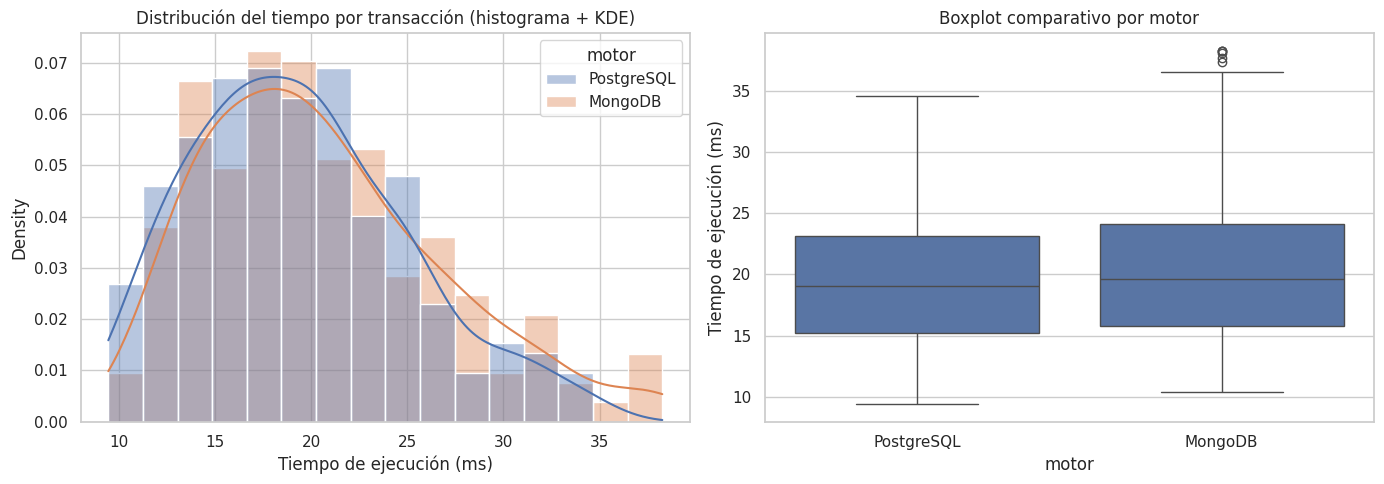

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_clean, x=VAR, hue=GRUPO, kde=True, stat="density",
             common_norm=False, alpha=0.4, ax=ax[0])
ax[0].set_title("Distribución del tiempo por transacción (histograma + KDE)")
ax[0].set_xlabel("Tiempo de ejecución (ms)")

sns.boxplot(data=df_clean, x=GRUPO, y=VAR, ax=ax[1])
ax[1].set_title("Boxplot comparativo por motor")
ax[1].set_ylabel("Tiempo de ejecución (ms)")

plt.tight_layout()
plt.show()

### 1.5 Interpretación del Bloque 1

1. **Calidad de datos:** no hubo valores ausentes (0 nulos en ambas columnas) y los tipos son correctos (`tiempo_ms` es numérico y `motor` es texto). Con el criterio 1.5×IQR se eliminaron 18 observaciones atípicas (10 de PostgreSQL y 8 de MongoDB), es decir, cerca del 3% de los datos. Quedaron 290 registros de PostgreSQL y 292 de MongoDB (N = 582), por lo que se cumple el requisito de al menos 200 por grupo y N ≥ 400.

2. **Tendencia central:** MongoDB tiene la media y la mediana más altas (media 20.59 ms y mediana 19.66 ms) frente a PostgreSQL (media 19.39 ms y mediana 19.07 ms). La diferencia entre medias es de aproximadamente 1.2 ms a favor de PostgreSQL. En el boxplot se aprecia lo mismo: la mediana y la caja de MongoDB están un poco más arriba, aunque las dos cajas se traslapan bastante.

3. **Dispersión:** MongoDB es más variable (desviación estándar de 6.23 ms y varianza de 38.86) que PostgreSQL (5.59 ms y 31.22). Su caja es algo más ancha y su bigote superior llega más arriba. Esto significa que los tiempos de MongoDB son menos predecibles.

4. **Sesgo:** ambos grupos tienen asimetría positiva (0.75 en MongoDB y 0.53 en PostgreSQL), con la media por encima de la mediana. Es decir, la mayoría de las transacciones son rápidas, pero hay algunas lentas que jalan el promedio hacia arriba. La curtosis es cercana a 0 en los dos casos (0.13 y -0.17), así que las colas no son especialmente pesadas.

5. **Forma:** los histogramas y las curvas KDE tienen una sola cima alrededor de 18 a 20 ms y una cola alargada hacia la derecha, por lo que no son normales perfectas. En el boxplot de MongoDB aparecen unos pocos puntos por encima del bigote superior; esto es normal, porque después de eliminar los atípicos los cuartiles se recalculan un poco y el criterio se aplicó una sola vez. Como los datos están algo sesgados, en el Bloque 2 se comprueba con el Teorema Central del Límite que las medias sí se comportan de forma aproximadamente normal.


# Bloque 2. Distribuciones de muestreo y Teorema Central del Límite

### 2.1 Muestra global y proceso de remuestreo

**Qué se hace:**
1. Se aísla la métrica `tiempo_ms` de **ambos grupos juntos** (N ≥ 400), que actúa como "población" observada.
2. Para cada tamaño muestral n ∈ {5, 15, 30, 60} se extraen **k = 1,000 muestras con reemplazo** y se calcula la media de cada una.

**Por qué:** la distribución de esas 1,000 medias es la **distribución muestral de la media**. El TCL establece que, aunque la población esté sesgada, esa distribución se acerca a una normal al crecer n, con error estándar σ/√n.

In [7]:
y_global = df_clean[VAR].to_numpy()
print(f"Tamaño de la muestra global: N = {len(y_global)}")
print(f"Media global = {y_global.mean():.3f} ms | s global = {y_global.std(ddof=1):.3f} ms")

K = 1000
TAMANOS = [5, 15, 30, 60]
rng = np.random.default_rng(SEED)

def remuestrear(datos, n, k, rng):
    """Devuelve las medias de k muestras de tamaño n, con reemplazo."""
    return np.array([rng.choice(datos, size=n, replace=True).mean() for _ in range(k)])

medias_por_n = {n: remuestrear(y_global, n, K, rng) for n in TAMANOS}
print("Remuestreo completado:", {n: len(m) for n, m in medias_por_n.items()}, "medias por tamaño")

Tamaño de la muestra global: N = 582
Media global = 19.992 ms | s global = 5.946 ms
Remuestreo completado: {5: 1000, 15: 1000, 30: 1000, 60: 1000} medias por tamaño


### 2.2 Cuadrícula 2 × 2 de las distribuciones de medias muestrales

**Qué se espera ver:** con n = 5 la distribución conserva parte del sesgo de la población y es ancha; al aumentar n se vuelve más simétrica (forma de campana) y más estrecha, centrada en la media global (línea roja).

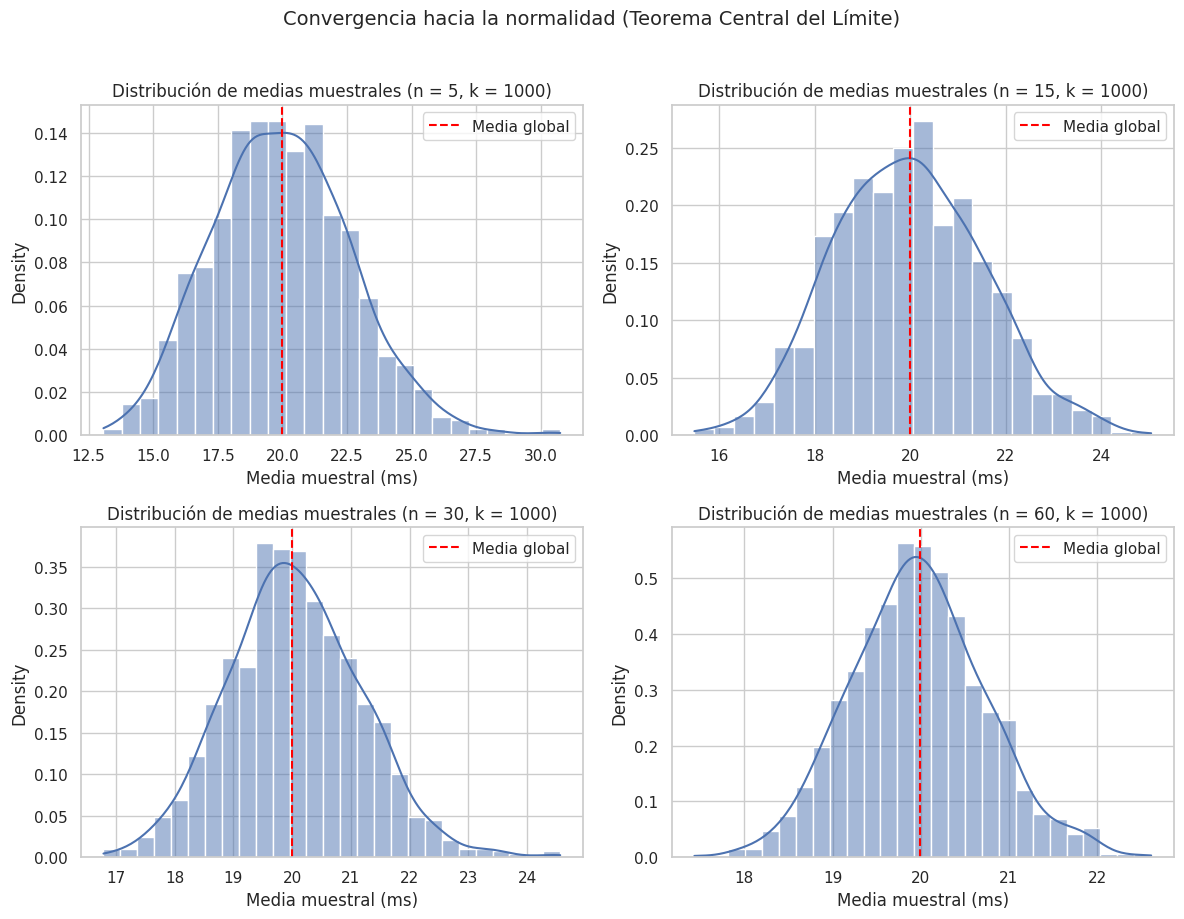

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, n in zip(axes.ravel(), TAMANOS):
    sns.histplot(medias_por_n[n], kde=True, stat="density", ax=ax)
    ax.axvline(y_global.mean(), color="red", linestyle="--", label="Media global")
    ax.set_title(f"Distribución de medias muestrales (n = {n}, k = {K})")
    ax.set_xlabel("Media muestral (ms)")
    ax.legend()
plt.suptitle("Convergencia hacia la normalidad (Teorema Central del Límite)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

### 2.3 Error estándar empírico vs. teórico

**Qué se compara:**
- **Error estándar empírico:** desviación estándar de las 1,000 medias muestrales.
- **Error estándar teórico:** $\sigma_{\bar{x}} = s/\sqrt{n}$, usando la desviación estándar muestral global s.

Se incluye también la asimetría y la curtosis de las medias: si tienden a 0 al subir n, se respalda la convergencia a la normalidad.

In [11]:
s_global = y_global.std(ddof=1)

filas = []
for n in TAMANOS:
    medias = medias_por_n[n]
    se_emp = medias.std(ddof=1)
    se_teo = s_global / np.sqrt(n)
    filas.append({
        "n": n,
        "media_de_las_medias": medias.mean(),
        "SE_empirico": se_emp,
        "SE_teorico (s/raiz n)": se_teo,
        "diferencia_%": abs(se_emp - se_teo) / se_teo * 100,
        "asimetria_de_medias": stats.skew(medias),
        "curtosis_de_medias": stats.kurtosis(medias),
    })

tabla_se = pd.DataFrame(filas).round(4)
display(tabla_se)

,n,media_de_las_medias,SE_empirico,SE_teorico (s/raiz n),diferencia_%,asimetria_de_medias,curtosis_de_medias
0,5,19.9794,2.6507,2.6590,0.3143,0.2746,0.1171
1,15,19.9678,1.5459,1.5352,0.6954,0.1566,-0.1770
2,30,20.0490,1.1310,1.0855,4.1844,0.2366,0.2721
3,60,19.9697,0.7634,0.7676,0.5410,0.1412,0.1059


### 2.4 Interpretación del Bloque 2

1. **Error estándar:** el error estándar empírico quedó muy cerca del teórico (s/√n) en los cuatro tamaños. La diferencia fue menor a 1% para n = 5, 15 y 60, y de 4.2% para n = 30, que sigue siendo pequeña y se explica por la variación natural de simular solo 1,000 muestras. Además, el error estándar baja al crecer n: pasa de 2.65 ms con n = 5 a 0.76 ms con n = 60, una reducción de aproximadamente 3.5 veces, que coincide con lo esperado (√(60/5) ≈ 3.46).

2. **Normalidad:** con n = 5 la distribución de medias es ancha y todavía tiene una ligera cola a la derecha; con n = 60 es una campana estrecha y simétrica centrada en la media global (cerca de 20 ms). La asimetría de las medias es pequeña en todos los casos (entre 0.14 y 0.27) y menor que la de los datos originales (0.53 y 0.75), y la curtosis queda cerca de 0. La asimetría no baja de forma perfectamente continua (n = 30 sube un poco), algo normal al trabajar con simulación.

3. **Conclusión:** a partir de n = 30 la distribución de medias ya luce prácticamente normal, aunque los tiempos individuales tengan sesgo. Esto justifica usar métodos basados en la normalidad de la media, como los intervalos t y la prueba t de los siguientes bloques; además, nuestras muestras reales son de unos 290 datos por grupo, mucho mayores que 30.


# Bloque 3. Estimación por intervalos de confianza

### 3.1 IC para la media poblacional general (μ) al 90%, 95% y 99%

**Selección de la distribución (justificación formal):**
- La desviación estándar poblacional σ es **desconocida** y se estima con s.
- Cuando σ es desconocida, el estadístico $\frac{\bar{x}-\mu}{s/\sqrt{n}}$ sigue una distribución **t-Student con n − 1 grados de libertad** (suponiendo normalidad de la media, respaldada por el TCL del Bloque 2).
- Por tanto se usa **t-Student**. Con n grande, t converge a Z, por lo que las diferencias son mínimas; abajo se muestran ambas solo como comparación.

$$\bar{x} \pm t_{\alpha/2,\,n-1}\cdot \frac{s}{\sqrt{n}}$$

In [12]:
def ic_media(datos, nivel):
    """IC para la media usando t-Student (sigma desconocida)."""
    n = len(datos)
    media, sem = datos.mean(), stats.sem(datos)
    t_lo, t_hi = stats.t.interval(nivel, df=n - 1, loc=media, scale=sem)
    z_lo, z_hi = stats.norm.interval(nivel, loc=media, scale=sem)   # solo comparación
    return {"nivel": f"{int(nivel*100)}%", "media": media,
            "t_inferior": t_lo, "t_superior": t_hi, "t_amplitud": t_hi - t_lo,
            "z_inferior": z_lo, "z_superior": z_hi}

tabla_ic_media = pd.DataFrame([ic_media(y_global, nv) for nv in (0.90, 0.95, 0.99)]).round(4)
display(tabla_ic_media)

,nivel,media,t_inferior,t_superior,t_amplitud,z_inferior,z_superior
0,90%,19.992,19.5859,20.3980,0.8121,19.5866,20.3973
1,95%,19.992,19.5079,20.4760,0.9681,19.5089,20.4750
2,99%,19.992,19.3550,20.6289,1.2739,19.3571,20.6268


**Interpretación:** a mayor nivel de confianza, mayor amplitud del intervalo (se gana seguridad a costa de precisión): el intervalo mide 0.81 ms al 90%, 0.97 ms al 95% y 1.27 ms al 99%. El IC al 95% para el tiempo medio por transacción (de ambos motores en conjunto) es **(19.51 ms, 20.48 ms)**. Esto significa que, con 95% de confianza, el tiempo medio verdadero está entre 19.51 y 20.48 ms. Los intervalos con t y con Z son prácticamente iguales porque n es grande (582 datos), pero se usó t por ser la opción correcta cuando σ es desconocida.

### 3.2 IC del 95% para la diferencia de medias (μ₁ − μ₂)

Se define **μ₁ = PostgreSQL** y **μ₂ = MongoDB**, de modo que un intervalo negativo indica que PostgreSQL es más rápido.

**Paso previo: prueba de Levene** (homogeneidad de varianzas).
- H₀: las varianzas de ambos grupos son iguales.
- Si p > 0.05, no hay evidencia contra la igualdad y se usa el IC con **varianzas combinadas (pooled)**.
- Si p ≤ 0.05, se usa la **corrección de Welch** (varianzas distintas y grados de libertad de Welch-Satterthwaite).

In [13]:
g1 = df_clean.loc[df_clean[GRUPO] == G1, VAR]
g2 = df_clean.loc[df_clean[GRUPO] == G2, VAR]

def ic_diferencia(g1, g2, nivel=0.95, alpha_levene=0.05):
    """IC para mu1 - mu2. Elige pooled o Welch segun la prueba de Levene."""
    n1, n2 = len(g1), len(g2)
    m1, m2 = g1.mean(), g2.mean()
    v1, v2 = g1.var(ddof=1), g2.var(ddof=1)

    lev_stat, lev_p = stats.levene(g1, g2)
    varianzas_iguales = lev_p > alpha_levene

    if varianzas_iguales:
        sp2 = ((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2)
        se = np.sqrt(sp2 * (1 / n1 + 1 / n2))
        gl = n1 + n2 - 2
        metodo = "Varianzas combinadas (pooled)"
    else:
        se = np.sqrt(v1 / n1 + v2 / n2)
        gl = (v1 / n1 + v2 / n2) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
        metodo = "Welch"

    dif = m1 - m2
    t_crit = stats.t.ppf(1 - (1 - nivel) / 2, gl)
    return {"levene_estadistico": lev_stat, "levene_p": lev_p,
            "varianzas_iguales": varianzas_iguales, "metodo": metodo,
            "diferencia": dif, "error_estandar": se, "gl": gl, "t_critico": t_crit,
            "ic_inf": dif - t_crit * se, "ic_sup": dif + t_crit * se}

res_ic = ic_diferencia(g1, g2, nivel=0.95)

print(f"Prueba de Levene: estadístico = {res_ic['levene_estadistico']:.4f}, p-value = {res_ic['levene_p']:.4f}")
print(f"¿Varianzas iguales (p > 0.05)? {res_ic['varianzas_iguales']}  ->  Método: {res_ic['metodo']}")
print(f"\nMedia {G1} = {g1.mean():.3f} ms | Media {G2} = {g2.mean():.3f} ms")
print(f"Diferencia de medias (mu1 - mu2) = {res_ic['diferencia']:.3f} ms")
print(f"Error estándar = {res_ic['error_estandar']:.4f} | gl = {res_ic['gl']:.2f} | t crítico = {res_ic['t_critico']:.4f}")
print(f"IC 95% para (mu1 - mu2): ({res_ic['ic_inf']:.3f}, {res_ic['ic_sup']:.3f}) ms")

# Verificación cruzada con scipy (disponible en scipy >= 1.10)
try:
    r = stats.ttest_ind(g1, g2, equal_var=res_ic["varianzas_iguales"])
    ci = r.confidence_interval(confidence_level=0.95)
    print(f"Verificación con scipy: ({ci.low:.3f}, {ci.high:.3f}) ms")
except Exception as e:
    print("Verificación con scipy no disponible:", e)

Prueba de Levene: estadístico = 2.0398, p-value = 0.1538
¿Varianzas iguales (p > 0.05)? True  ->  Método: Varianzas combinadas (pooled)

Media PostgreSQL = 19.390 ms | Media MongoDB = 20.590 ms
Diferencia de medias (mu1 - mu2) = -1.199 ms
Error estándar = 0.4908 | gl = 580.00 | t crítico = 1.9641
IC 95% para (mu1 - mu2): (-2.163, -0.235) ms
Verificación con scipy: (-2.163, -0.235) ms


### 3.3 ¿El cero pertenece al intervalo? (0 ∈ IC)

**Cómo se lee:** el cero representa "no hay diferencia entre medias".
- Si **0 ∉ IC**: con 95% de confianza, las medias son distintas, y el signo del intervalo indica cuál motor es más rápido.
- Si **0 ∈ IC**: la diferencia observada es compatible con el azar; no se puede afirmar que un motor sea más rápido.

In [14]:
cero_en_ic = res_ic["ic_inf"] <= 0 <= res_ic["ic_sup"]
print(f"¿0 pertenece al IC 95%? {cero_en_ic}")

if cero_en_ic:
    print("Lectura: el IC incluye 0, no hay evidencia de diferencia entre los motores.")
elif res_ic["ic_sup"] < 0:
    print(f"Lectura: todo el IC es negativo; {G1} tarda entre {abs(res_ic['ic_sup']):.2f} y "
          f"{abs(res_ic['ic_inf']):.2f} ms MENOS por transacción que {G2} (95% de confianza).")
else:
    print(f"Lectura: todo el IC es positivo; {G1} tarda entre {res_ic['ic_inf']:.2f} y "
          f"{res_ic['ic_sup']:.2f} ms MÁS por transacción que {G2} (95% de confianza).")

¿0 pertenece al IC 95%? False
Lectura: todo el IC es negativo; PostgreSQL tarda entre 0.24 y 2.16 ms MENOS por transacción que MongoDB (95% de confianza).


### 3.4 Interpretación del Bloque 3

1. **Levene:** se obtuvo un estadístico de 2.04 y un p-value de 0.1538. Como p > 0.05, no hay evidencia de que las varianzas sean distintas (aunque la de MongoDB sea algo mayor, esa diferencia puede deberse al azar). Por eso se usó el intervalo con **varianzas combinadas (pooled)**. El resultado coincidió con la verificación hecha con scipy.

2. **IC de la diferencia:** la diferencia de medias (μ_PostgreSQL − μ_MongoDB) fue de −1.20 ms y el IC al 95% fue **(−2.16 ms, −0.24 ms)**. Es decir, con 95% de confianza, PostgreSQL tarda entre 0.24 y 2.16 ms menos por transacción que MongoDB.

3. **Impacto práctico de 0 ∈ IC:** el cero no pertenece al intervalo (todo el intervalo es negativo), así que la diferencia no es compatible con "no hay diferencia" y se considera real. Sin embargo, la magnitud es pequeña: 1.2 ms es cerca del 6% del tiempo promedio (alrededor de 20 ms) y, en el extremo inferior del intervalo, apenas 0.24 ms (aprox. 1%). Que sea estadísticamente significativa no significa que sea grande; si el sistema tiene un límite de servicio (SLA) de varios milisegundos por transacción, esta diferencia probablemente no cambiaría el cumplimiento, aunque con millones de transacciones sí se acumularía.


# Bloque 4. Teoría de decisión (prueba de hipótesis)

### 4.1 Planteamiento formal de hipótesis

El problema pide **contrastar si existe diferencia** entre los motores, por lo que la prueba es **bilateral**:

- **H₀:** μ_PostgreSQL = μ_MongoDB (el tiempo medio por transacción es el mismo en ambos motores).
- **H₁:** μ_PostgreSQL ≠ μ_MongoDB (el tiempo medio por transacción es diferente).

### 4.2 Matriz de decisión y costo de los errores

| Decisión \ Realidad | H₀ verdadera (no hay diferencia) | H₀ falsa (sí hay diferencia) |
|---|---|---|
| **Rechazar H₀** | **Error Tipo I (α):** concluir que un motor es más rápido cuando en realidad son equivalentes. | Decisión correcta (potencia = 1 − β) |
| **No rechazar H₀** | Decisión correcta | **Error Tipo II (β):** no detectar una diferencia real de rendimiento. |

**Costo operativo / técnico:**
- **Error Tipo I (α):** se podría migrar o rediseñar el almacenamiento hacia el motor "más rápido" sin ganancia real; costo de migración, reescritura de consultas, capacitación y riesgo de regresiones.
- **Error Tipo II (β):** se mantendría el motor menos eficiente creyendo que son equivalentes; costo de mayor tiempo de respuesta acumulado, uso de más recursos de cómputo y posible incumplimiento de objetivos de nivel de servicio a escala.

### 4.3 Nivel de significancia

Se fija **α = 0.05**: se acepta un 5% de probabilidad de cometer un Error Tipo I. Se considera razonable porque el costo de una migración innecesaria es moderado, pero no despreciable.

### 4.4 Ejecución de la prueba t para muestras independientes

Se usa `scipy.stats.ttest_ind`, con `equal_var` determinado por el resultado de Levene del Bloque 3 (pooled o Welch), para mantener coherencia con el intervalo de confianza.

In [15]:
t_stat, p_value = stats.ttest_ind(g1, g2, equal_var=res_ic["varianzas_iguales"])

# Tamaño del efecto (d de Cohen) para complementar la significancia estadística
n1, n2 = len(g1), len(g2)
sp = np.sqrt(((n1 - 1) * g1.var(ddof=1) + (n2 - 1) * g2.var(ddof=1)) / (n1 + n2 - 2))
d_cohen = (g1.mean() - g2.mean()) / sp

print(f"Método: {res_ic['metodo']} (equal_var = {res_ic['varianzas_iguales']})")
print(f"Estadístico t calculado = {t_stat:.4f}")
print(f"p-value (bilateral)     = {p_value:.6f}")
print(f"Nivel de significancia  = {ALPHA}")
print(f"d de Cohen              = {d_cohen:.3f}  (|d|: ~0.2 pequeño, ~0.5 mediano, ~0.8 grande)")

Método: Varianzas combinadas (pooled) (equal_var = True)
Estadístico t calculado = -2.4435
p-value (bilateral)     = 0.014845
Nivel de significancia  = 0.05
d de Cohen              = -0.203  (|d|: ~0.2 pequeño, ~0.5 mediano, ~0.8 grande)


### 4.5 Veredicto formal y recomendación técnica

**Regla de decisión:** si p-value < α, se rechaza H₀; en caso contrario, no se rechaza H₀. (Nunca se dice "aceptar H₀": solo se afirma que no hay evidencia suficiente en su contra.)

In [16]:
if p_value < ALPHA:
    veredicto = "RECHAZAR H0"
    mas_rapido = G1 if g1.mean() < g2.mean() else G2
    print(f"Veredicto: {veredicto} (p = {p_value:.6f} < alpha = {ALPHA})")
    print(f"Hay evidencia estadística de diferencia entre los motores; "
          f"en promedio {mas_rapido} es más rápido por transacción.")
else:
    veredicto = "NO RECHAZAR H0"
    print(f"Veredicto: {veredicto} (p = {p_value:.6f} >= alpha = {ALPHA})")
    print("No hay evidencia suficiente de diferencia en el tiempo medio por transacción.")

print(f"\nCoherencia con el IC del Bloque 3 (0 in IC = {cero_en_ic}): "
      f"{'consistente' if (p_value < ALPHA) == (not cero_en_ic) else 'REVISAR'}")

Veredicto: RECHAZAR H0 (p = 0.014845 < alpha = 0.05)
Hay evidencia estadística de diferencia entre los motores; en promedio PostgreSQL es más rápido por transacción.

Coherencia con el IC del Bloque 3 (0 in IC = False): consistente


**Recomendación técnica de ingeniería**

Se **rechaza H₀** (t = −2.44, p = 0.0148 < 0.05): hay evidencia estadística de que el tiempo medio por transacción es distinto entre los motores, y PostgreSQL resulta más rápido, con una diferencia de aproximadamente 1.2 ms (IC 95%: entre 0.24 y 2.16 ms). Sin embargo, el tamaño del efecto es pequeño (d de Cohen = −0.20), por lo que la ventaja de velocidad, por sí sola, no justifica migrar de un motor a otro. Recomendamos elegir el motor según otros criterios que pesan más en el proyecto, como el modelo de datos, la necesidad de transacciones ACID, la escalabilidad horizontal y la experiencia del equipo, y considerar a PostgreSQL como ligera ventaja de rendimiento a igualdad de condiciones. Al rechazar H₀ existe un 5% de riesgo de Error Tipo I, y una limitación importante es que los datos son sintéticos (simulados), por lo que el resultado depende de los parámetros elegidos y conviene validarlo con pruebas de carga reales sobre ambos motores antes de decidir.


# Conclusiones generales

1. **Bloque 1:** los datos estaban completos y, tras quitar 18 valores atípicos, quedaron 582 registros. Los tiempos de ambos motores son parecidos (cerca de 20 ms), con algo de sesgo a la derecha: MongoDB es un poco más lento y más variable que PostgreSQL.

2. **Bloque 2:** la simulación confirmó el Teorema Central del Límite: aunque los tiempos individuales no son perfectamente normales, las medias muestrales sí lo son a partir de n = 30, y el error estándar empírico coincidió con el teórico (s/√n).

3. **Bloque 3:** el tiempo medio general está entre 19.51 y 20.48 ms (IC 95%). La diferencia entre motores es de unos 1.2 ms a favor de PostgreSQL y el cero queda fuera del intervalo (−2.16 a −0.24 ms), así que la diferencia es real.

4. **Bloque 4:** la prueba t rechazó la hipótesis nula (p = 0.0148), es decir, sí hay diferencia entre los motores, pero el efecto es pequeño (d = −0.20).

5. **Recomendación final y limitaciones:** PostgreSQL es ligeramente más rápido, pero la diferencia es tan chica que no debería ser la única razón para elegirlo. La decisión debe considerar también el tipo de datos y las necesidades del proyecto. Como los datos fueron simulados, conviene confirmar estos resultados con pruebas reales antes de tomar una decisión definitiva.
